# Hierarchical VQ-VAE (VQ-VAE-2 Style)

VQ-VAE-2 extends discrete latents to multiple spatial scales. This notebook implements a compact two-level version: a top code grid represents coarser features, and a bottom code grid is formed using both image features and the upsampled top representation. The decoder combines both quantized levels. This is an educational simplified model, not a reproduction of the full high-resolution VQ-VAE-2 architecture.

## Coarse and fine discrete representations

The bottom-up encoder computes image features, then a top encoder compresses them to a smaller spatial grid. The top grid is vector-quantized first. Its embeddings are upsampled and combined with bottom encoder features before the bottom grid is quantized. The decoder uses both grids.

Each level uses nearest-code assignment, a straight-through estimator, codebook loss, and commitment loss. We track the code usage and perplexity at both levels. In a full VQ-VAE-2 generation system, separate learned priors model top-level codes and bottom-level codes conditioned on top-level codes. This notebook trains the autoencoder and inspects reconstructions/code usage; it does not train those autoregressive priors.

In [1]:
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [2]:
transform = transforms.Compose([transforms.Resize(32), transforms.ToTensor()])
train_data = datasets.MNIST('data', train=True, download=True, transform=transform)
test_data = datasets.MNIST('data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False)

## Vector quantizer shared by both levels

Each latent grid location selects its nearest embedding. The forward path uses the codebook vector; the backward path copies gradients through the encoder features using the straight-through estimator.

In [3]:
class VectorQuantizer(nn.Module):
    def __init__(self, num_codes, code_dim, commitment_beta=0.25):
        super().__init__()
        self.embedding = nn.Embedding(num_codes, code_dim)
        nn.init.uniform_(self.embedding.weight, -1 / num_codes, 1 / num_codes)
        self.commitment_beta = commitment_beta

    def forward(self, z_e):
        b, d, h, w = z_e.shape
        vectors = z_e.permute(0, 2, 3, 1).contiguous()
        flat = vectors.view(-1, d)
        distances = flat.square().sum(1, keepdim=True) + self.embedding.weight.square().sum(1) - 2 * flat @ self.embedding.weight.t()
        indices = distances.argmin(dim=1)
        z_q = self.embedding(indices).view(b, h, w, d)
        codebook_loss = F.mse_loss(z_q, vectors.detach())
        commitment_loss = F.mse_loss(vectors, z_q.detach())
        loss = codebook_loss + self.commitment_beta * commitment_loss
        z_st = vectors + (z_q - vectors).detach()
        counts = torch.bincount(indices, minlength=self.embedding.num_embeddings).float()
        probs = counts / counts.sum().clamp_min(1)
        perplexity = torch.exp(-(probs * torch.log(probs + 1e-10)).sum())
        return z_st.permute(0, 3, 1, 2).contiguous(), loss, indices.view(b, h, w), perplexity

class HierarchicalVQVAE(nn.Module):
    def __init__(self, top_codes=64, bottom_codes=128):
        super().__init__()
        # 32x32 -> 8x8 bottom-up feature grid
        self.bottom_encoder = nn.Sequential(
            nn.Conv2d(1, 32, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU())
        # 8x8 -> 4x4 top grid
        self.top_encoder = nn.Sequential(nn.Conv2d(64, 32, 4, 2, 1), nn.ReLU())
        self.top_quantizer = VectorQuantizer(top_codes, 32)
        self.bottom_condition = nn.Sequential(nn.Conv2d(64 + 32, 64, 1), nn.ReLU())
        self.bottom_quantizer = VectorQuantizer(bottom_codes, 64)
        self.decoder_input = nn.Sequential(nn.Conv2d(64 + 32, 64, 3, padding=1), nn.ReLU())
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 4, 2, 1), nn.Sigmoid())

    def forward(self, x):
        bottom_features = self.bottom_encoder(x)
        top_features = self.top_encoder(bottom_features)
        top_q, top_loss, top_indices, top_perplexity = self.top_quantizer(top_features)
        top_up = F.interpolate(top_q, size=bottom_features.shape[-2:], mode='nearest')
        bottom_input = self.bottom_condition(torch.cat([bottom_features, top_up], dim=1))
        bottom_q, bottom_loss, bottom_indices, bottom_perplexity = self.bottom_quantizer(bottom_input)
        decoder_input = self.decoder_input(torch.cat([bottom_q, top_up], dim=1))
        reconstruction = self.decoder(decoder_input)
        return reconstruction, (top_loss, bottom_loss), (top_indices, bottom_indices), (top_perplexity, bottom_perplexity)

model = HierarchicalVQVAE().to(device)

## Train and monitor both codebooks

The total objective adds reconstruction BCE to the two quantizer losses. The two perplexities summarize the effective number of codes selected in each batch. They are diagnostics, not targets to maximize blindly.

In [4]:
optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)
def run_epoch(loader, training):
    model.train(training)
    totals = torch.zeros(4)
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for x, _ in loader:
            x = x.to(device)
            if training: optimizer.zero_grad()
            reconstruction, (top_loss, bottom_loss), _, (top_ppl, bottom_ppl) = model(x)
            recon_loss = F.binary_cross_entropy(reconstruction, x)
            loss = recon_loss + top_loss + bottom_loss
            if training:
                loss.backward(); optimizer.step()
            totals += torch.tensor([loss.item(), recon_loss.item(), top_ppl.item(), bottom_ppl.item()]) * x.size(0)
    return (totals / len(loader.dataset)).tolist()

epochs = 50
history = []
for epoch in range(1, epochs + 1):
    metrics = run_epoch(train_loader, True)
    history.append(metrics)
    print(f'Epoch {epoch:02d} | total {metrics[0]:.4f} | recon {metrics[1]:.4f} | top perplexity {metrics[2]:.1f} | bottom perplexity {metrics[3]:.1f}')

Epoch 01 | total 36.1380 | recon 0.2603 | top perplexity 1.7 | bottom perplexity 2.0
Epoch 02 | total 0.1740 | recon 0.1320 | top perplexity 3.0 | bottom perplexity 8.3
Epoch 03 | total 0.1347 | recon 0.1180 | top perplexity 2.2 | bottom perplexity 9.5
Epoch 04 | total 0.1310 | recon 0.1138 | top perplexity 2.8 | bottom perplexity 9.8
Epoch 05 | total 0.1280 | recon 0.1113 | top perplexity 2.4 | bottom perplexity 9.8
Epoch 06 | total 0.1278 | recon 0.1104 | top perplexity 2.2 | bottom perplexity 10.1
Epoch 07 | total 0.1270 | recon 0.1095 | top perplexity 2.0 | bottom perplexity 10.4
Epoch 08 | total 0.1262 | recon 0.1088 | top perplexity 2.0 | bottom perplexity 10.4
Epoch 09 | total 0.1260 | recon 0.1081 | top perplexity 2.0 | bottom perplexity 10.4
Epoch 10 | total 0.1257 | recon 0.1074 | top perplexity 2.0 | bottom perplexity 10.3
Epoch 11 | total 0.1254 | recon 0.1069 | top perplexity 2.0 | bottom perplexity 10.2
Epoch 12 | total 0.1244 | recon 0.1063 | top perplexity 2.0 | bottom 

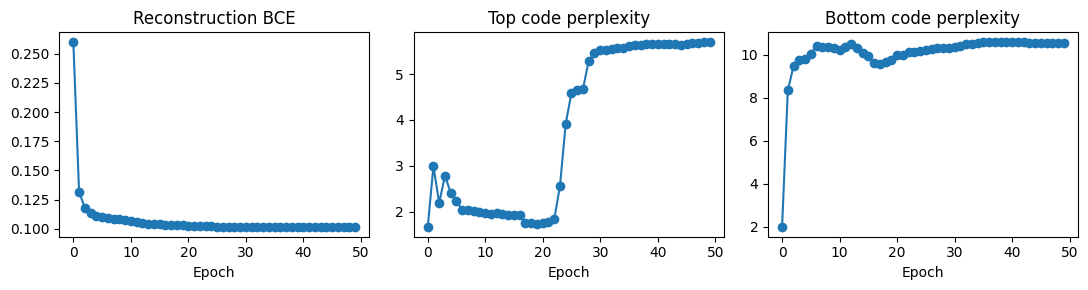

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, index, title in zip(axes, [1, 2, 3], ['Reconstruction BCE', 'Top code perplexity', 'Bottom code perplexity']):
    ax.plot([row[index] for row in history], marker='o'); ax.set(title=title, xlabel='Epoch')
plt.tight_layout(); plt.show()

## Inspect reconstructions and both code grids

The top grid is smaller and spatially coarser than the bottom grid. Their code indices can be inspected separately. A top-level code is not guaranteed to have a human-readable global meaning; this is an architectural bias, not a semantic guarantee.

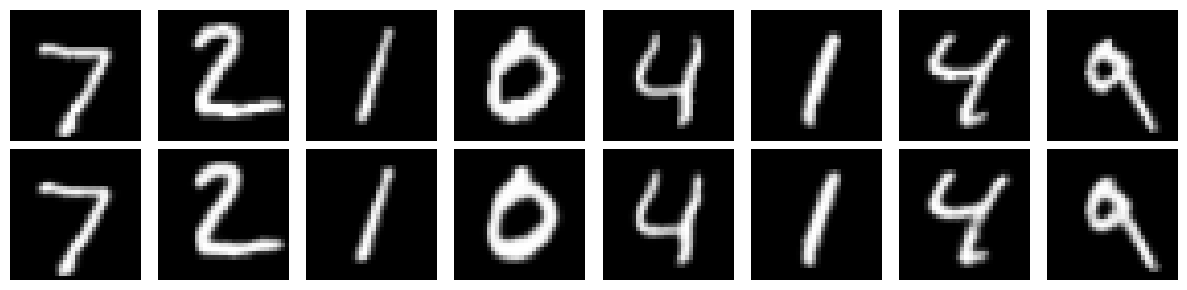

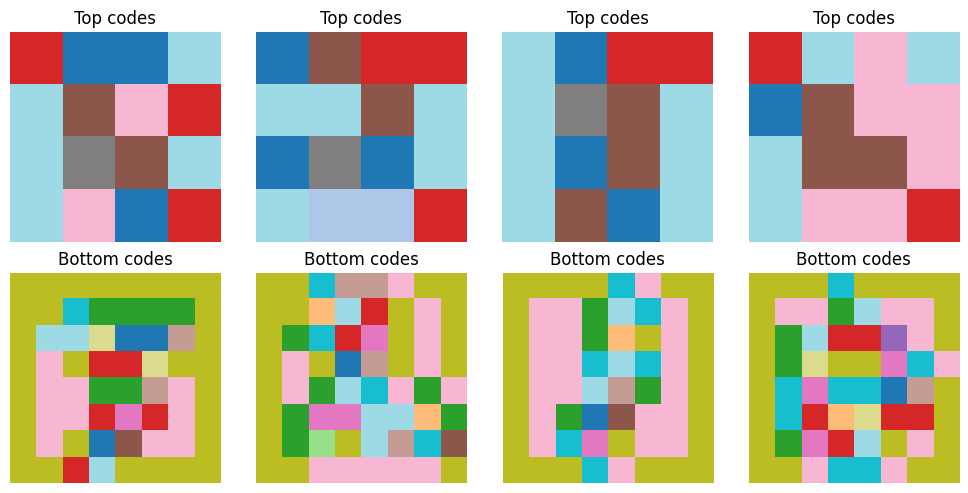

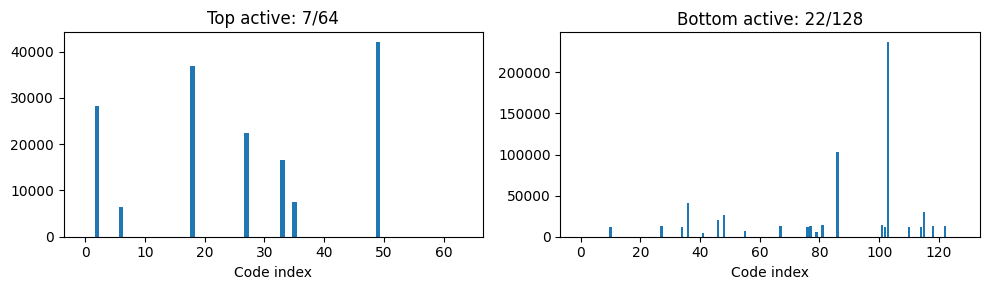

In [6]:
images, _ = next(iter(test_loader))
images = images[:8].to(device)
model.eval()
with torch.no_grad(): recon, _, (top_idx, bottom_idx), _ = model(images)
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    axes[0, i].imshow(images[i, 0].cpu(), cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(recon[i, 0].cpu(), cmap='gray'); axes[1, i].axis('off')
axes[0, 0].set_ylabel('Input'); axes[1, 0].set_ylabel('Reconstruction')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i in range(4):
    axes[0, i].imshow(top_idx[i].cpu(), interpolation='nearest', cmap='tab20'); axes[0, i].set_title('Top codes'); axes[0, i].axis('off')
    axes[1, i].imshow(bottom_idx[i].cpu(), interpolation='nearest', cmap='tab20'); axes[1, i].set_title('Bottom codes'); axes[1, i].axis('off')
plt.tight_layout(); plt.show()

@torch.no_grad()
def code_usage(loader, quantizer_index):
    quantizer = [model.top_quantizer, model.bottom_quantizer][quantizer_index]
    counts = torch.zeros(quantizer.embedding.num_embeddings)
    for x, _ in loader:
        _, _, (top, bottom), _ = model(x.to(device))
        indices = (top if quantizer_index == 0 else bottom).flatten().cpu()
        counts += torch.bincount(indices, minlength=len(counts))
    return counts

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for i, name in enumerate(['Top', 'Bottom']):
    counts = code_usage(test_loader, i)
    axes[i].bar(range(len(counts)), counts.numpy())
    axes[i].set(title=f'{name} active: {(counts > 0).sum().item()}/{len(counts)}', xlabel='Code index')
plt.tight_layout(); plt.show()

## Takeaways and knowledge check

This two-level model makes the top code grid condition the bottom feature grid, then decodes from both. It illustrates a coarse-to-fine discrete representation. The full VQ-VAE-2 generation pipeline additionally trains a prior over top codes and a conditional prior over bottom codes. Codebooks only define the token vocabularies; they do not model which code sequences are likely.

Monitor reconstruction and utilization at each level. Hierarchical models add compute and optimization complexity, and codebook collapse can still happen. A higher perplexity is not automatically better; evaluate whether codes support the task and produce useful reconstructions.